# 04: PCA

**The algorithm.** Find the directions along which the data varies most.

**Two ways to compute it.**
- **Full SVD** of the n × d data. Exact and general, but the work grows as n × d², and it copies the data.
- **Covariance + eigen-solve.** Build the d × d covariance matrix (one big multiply), then take its eigenvectors (a tiny problem). For tall data (n much larger than d) this does far less work. Our engines use this.

scikit-learn offers several solvers. Its default, `svd_solver="auto"`, picks one for you, and recent versions pick the covariance method for tall data. This notebook races the solvers *and* the engines, because **choosing the right algorithm can matter more than choosing the fastest engine.**

There's no Rust engine for the same reason as Ridge: the cost is one multiply that Rust would hand to the same BLAS routine NumPy uses.

In [1]:
import sys
sys.path.insert(0, ".")  # so bench_utils (next to this notebook) imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ml_in_rust as mr
from bench_utils import (machine_info, timeit, load_covtype, add_speedup,
                         save_results, line_chart, fmt_ms, only_available)

pd.set_option("display.float_format", "{:,.4f}".format)
%matplotlib inline
pd.Series(machine_info())

machine                                    macos-arm64-apple-m4
cpu                                                    Apple M4
cores                              4 performance + 6 efficiency
ram_gb                                                       24
os                          macOS-26.6.1-arm64-arm-64bit-Mach-O
python                                                   3.13.5
numpy                                  2.5.4 (BLAS: accelerate)
sklearn                                                   1.9.1
rust-blas matrix library                       Apple Accelerate
mlx                                     0.32.4 (Device(gpu, 0))
dtype: object

In [2]:
import os
QUICK = os.environ.get("QUICK") == "1"  # QUICK=1 ./run_all.sh for a fast smoke run
from sklearn.decomposition import PCA as SkPCA

def make_data(n, d, seed=0):
    rng = np.random.default_rng(seed)
    # Low-rank structure plus noise, with distinct variances so components are well defined.
    latent = rng.standard_normal((n, 12), dtype=np.float32) * np.linspace(5, 1, 12, dtype=np.float32)
    mixing = rng.standard_normal((12, d)).astype(np.float32)
    return latent @ mixing + rng.standard_normal((n, d), dtype=np.float32) * 0.5 + 3

def race(n, d, n_components=10, include_full=True):
    X = make_data(n, d)
    models = only_available({
        "sklearn (svd_solver=full)": lambda: SkPCA(n_components, svd_solver="full"),
        "sklearn (svd_solver=auto)": lambda: SkPCA(n_components),
        "sklearn (svd_solver=randomized)": lambda: SkPCA(n_components, svd_solver="randomized", random_state=0),
        "numpy": lambda: mr.PCA(n_components, backend="numpy"),
        "mlx": lambda: mr.PCA(n_components, backend="mlx"),
    })
    if not include_full:
        models.pop("sklearn (svd_solver=full)")
    out, ref = [], None
    for name, make in models.items():
        fitted = {}
        def run():
            fitted["m"] = make().fit(X)
        t = timeit(run, repeats=2)
        m = fitted["m"]
        if ref is None:
            ref = m
        out.append({"rows": n, "features": d, "engine": name, "fit s": t,
                    "solver used": getattr(m, "_fit_svd_solver", "covariance eigh"),
                    "variance ratio error": float(np.abs(m.explained_variance_ratio_ - ref.explained_variance_ratio_).max())})
    df = pd.DataFrame(out)
    base = df.loc[df["engine"] == "sklearn (svd_solver=auto)", "fit s"].iloc[0]
    df["vs sklearn default"] = base / df["fit s"]
    return df

## Race 1: more rows (100 features, 10 components)

"vs sklearn default" compares against `PCA()` with no solver argument, which is what most people run.

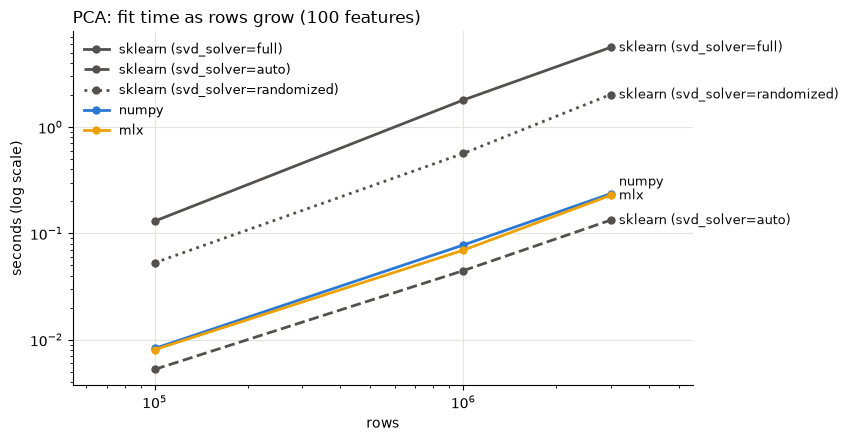

,rows,features,engine,fit s,solver used,variance ratio error,vs sklearn default
0,100000,100,sklearn (svd_solver=full),0.1302,full,0.0000,0.0403
1,100000,100,sklearn (svd_solver=auto),0.0053,covariance_eigh,0.0000,1.0000
2,100000,100,sklearn (svd_solver=randomized),0.0528,randomized,0.0000,0.0995
3,100000,100,numpy,0.0083,covariance eigh,0.0000,0.6356
4,100000,100,mlx,0.0081,covariance eigh,0.0000,0.6523
5,1000000,100,sklearn (svd_solver=full),1.7919,full,0.0000,0.0249
6,1000000,100,sklearn (svd_solver=auto),0.0446,covariance_eigh,0.0001,1.0000
7,1000000,100,sklearn (svd_solver=randomized),0.5640,randomized,0.0000,0.0790
8,1000000,100,numpy,0.0776,covariance eigh,0.0000,0.5743
9,1000000,100,mlx,0.0695,covariance eigh,0.0000,0.6416


In [3]:
SIZES = [100_000, 300_000] if QUICK else [100_000, 1_000_000, 3_000_000]
by_rows = pd.concat([race(n, 100) for n in SIZES], ignore_index=True)
line_chart(by_rows, "rows", "fit s", "PCA: fit time as rows grow (100 features)", "rows", "seconds (log scale)")
plt.show()
by_rows

## Race 2: more features (500k rows)

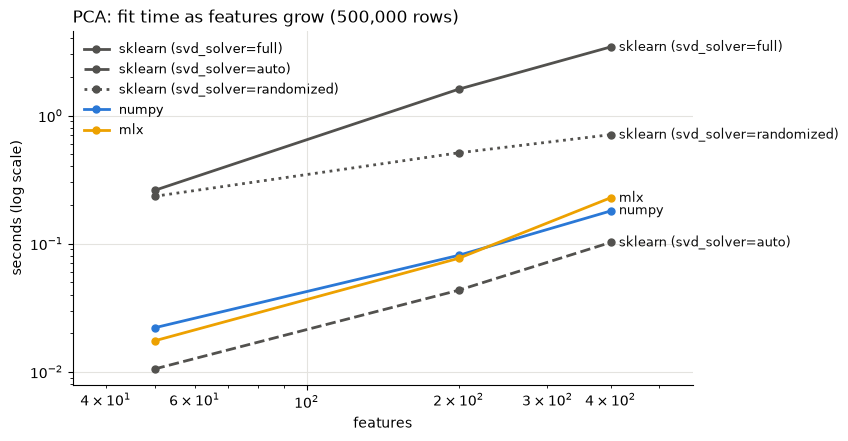

engine,mlx,numpy,sklearn (svd_solver=auto),sklearn (svd_solver=full),sklearn (svd_solver=randomized)
features,,,,,
50,0.6000,0.4800,1.0000,0.0400,0.0400
200,0.5600,0.5300,1.0000,0.0300,0.0800
400,0.4500,0.5700,1.0000,0.0300,0.1400


In [4]:
n = 100_000 if QUICK else 500_000
by_d = pd.concat([race(n, d) for d in [50, 200, 400]], ignore_index=True)
line_chart(by_d, "features", "fit s", f"PCA: fit time as features grow ({n:,} rows)", "features", "seconds (log scale)")
plt.show()
by_d.pivot(index="features", columns="engine", values="vs sklearn default").round(2)

In [5]:
save_results("pca", by_rows, notes={"by_features": by_d.to_dict(orient="records")})
print("Largest error in explained-variance ratio vs the exact full SVD:",
      f"{pd.concat([by_rows, by_d])['variance ratio error'].max():.2e}")

Largest error in explained-variance ratio vs the exact full SVD: 3.40e-04
